Decision Tree and Random Forest Classification

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
#Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = iris.target_names

print('Features:', feature_names)
print('Classes:', class_names)
print('Dataset shape:', X.shape)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Dataset shape: (150, 4)


In [4]:
#Convert dataset into a Dataframe for easy understanding
df = pd.DataFrame(X, columns=feature_names)
df['Target'] = y
df['Species'] = df['Target'].map(dict(enumerate(class_names)))

display(df.head(10))
print('\nDataset information:')
print(df.info())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target             150 non-null    int64  
 5   Species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


In [6]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 120
Testing samples: 30


1. Decision Tree Classifier

In [7]:
#Create and Train Decision Tree model
dt_model = DecisionTreeClassifier(criterion='entropy', random_state=42)

dt_model.fit(X_train, y_train)

print('Decision Tree model trained successfully.')

Decision Tree model trained successfully.


In [8]:
#Prediction and test score for Decision Tree
dt_pred = dt_model.predict(X_test)
dt_test_score = dt_model.score(X_test, y_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

print('Decision Tree Predictions:')
print(dt_pred)
print('\nDecision Tree test score:', round(dt_test_score, 4))
print('Decision Tree accuracy:', round(dt_accuracy, 4))

print('\nClassification Report:')
print(classification_report(y_test, dt_pred, target_names=class_names))

Decision Tree Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Decision Tree test score: 0.9333
Decision Tree accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


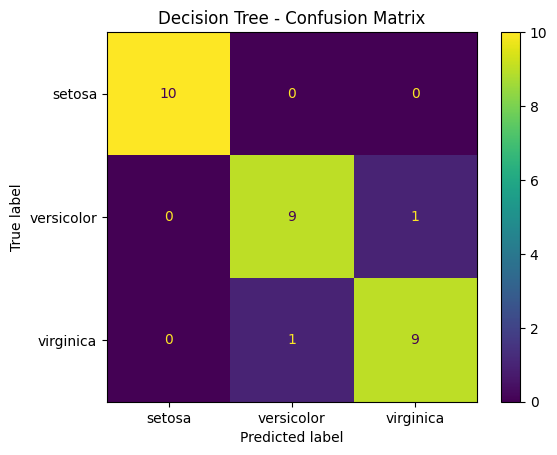

In [9]:
#Confusion Matrix - Decision Tree
dt_cm = confusion_matrix(y_test, dt_pred)

print('Decision Tree Confusion Matrix:')
print(dt_cm)

disp = ConfusionMatrixDisplay(confusion_matrix=dt_cm, display_labels=class_names)
disp.plot()
plt.title('Decision Tree - Confusion Matrix')
plt.show()

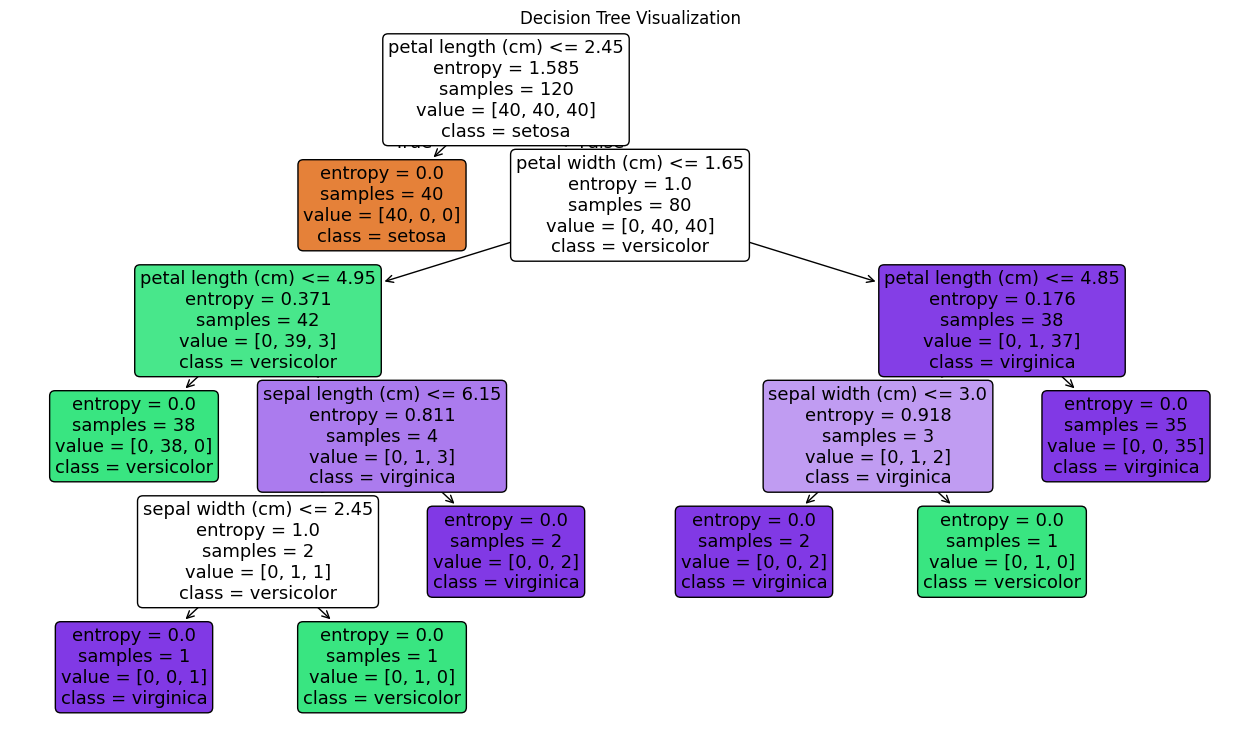

In [10]:
#Visualize the Decision Tree
plt.figure(figsize=(16, 9))
plot_tree(dt_model, feature_names=feature_names, class_names=class_names, filled=True, rounded=True)
plt.title('Decision Tree Visualization')
plt.show()

2. Random Forest Classifier

In [11]:
#Create and train Random forest model
rf_model = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=42)

rf_model.fit(X_train, y_train)

print('Random Forest model trained successfully.')

Random Forest model trained successfully.


In [12]:
#Predition and test score for Random Forest
rf_pred = rf_model.predict(X_test)
rf_test_score = rf_model.score(X_test, y_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print('Random Forest Predictions:')
print(rf_pred)
print('\nRandom Forest test score:', round(rf_test_score, 4))
print('Random Forest accuracy:', round(rf_accuracy, 4))

print('\nClassification Report:')
print(classification_report(y_test, rf_pred, target_names=class_names))

Random Forest Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 2 2 2 1 0 2 0]

Random Forest test score: 0.9333
Random Forest accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Random Forest Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


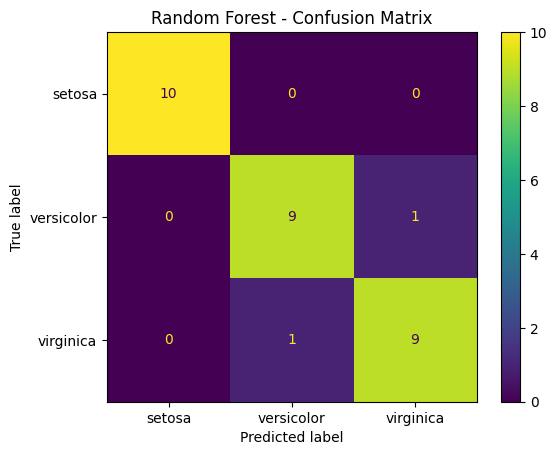

In [13]:
#Confusion Matrix - Random Forest
rf_cm = confusion_matrix(y_test, rf_pred)

print('Random Forest Confusion Matrix:')
print(rf_cm)

disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=class_names)
disp.plot()
plt.title('Random Forest - Confusion Matrix')
plt.show()

3. Predictionon New data

In [22]:
#Predict the class of a new flower
#[sepal length, sepal width, petal length, petal width]
new_data = np.array([[5.1, 3.5, 1.4, 0.2]])

dt_new = dt_model.predict(new_data)[0]
rf_new = rf_model.predict(new_data)[0]

print('New Data:', new_data[0])

print('Decision Tree Prediction:', class_names[dt_new])
print('Random Forest Prediction:', class_names[rf_new])

New Data: [5.1 3.5 1.4 0.2]
Decision Tree Prediction: setosa
Random Forest Prediction: setosa


In [23]:
#Compare both models
comparison = pd.DataFrame({'Model':['Decision Tree', 'Random Forest'],
    'Test Score': [dt_test_score, rf_test_score],
    'Accuracy': [dt_accuracy, rf_accuracy]})

comparison['Test Score'] = comparison['Test Score'].round(4)
comparison['Accuracy'] = comparison['Accuracy'].round(4)
display(comparison)

,Model,Test Score,Accuracy
0,Decision Tree,0.9333,0.9333
1,Random Forest,0.9333,0.9333
